In [1]:
import os
import sys
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


sys.path.append("..")
from src import config
from src.hal import SimulatedHAL
from src.controller import IrrigationController

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

print("    Setup complete")
print(f"   HARDWARE_MODE:    {config.HARDWARE_MODE}")
print(f"   SIMULATION_CSV:   {os.path.basename(config.SIMULATION_CSV)}")
print(f"   CSV exists:       {os.path.exists(config.SIMULATION_CSV)}")
print(f"   Window size:      {config.WINDOW_SIZE} steps")
print(f"   Predict horizon:  {config.PREDICT_HORIZON} steps")

    Setup complete
   HARDWARE_MODE:    simulated
   SIMULATION_CSV:   bhopal_agritech_dry_v2.csv
   CSV exists:       True
   Window size:      30 steps
   Predict horizon:  60 steps


In [2]:

soil_model = None

if os.path.exists(config.SOIL_MODEL_KERAS):
    try:
        from src.predict import SoilPredictor
        soil_model = SoilPredictor.load()
        print(" LSTM predictor loaded — Policy C uses trained ML")
    except Exception as e:
        print(f" Could not load LSTM: {e}")
        print("   Policy C will use linear extrapolation fallback.")
else:
    print("    No LSTM found — Policy C uses linear extrapolation fallback.")
    print(f"   Train one with: python -m src.train_soil --epochs 30")

 Loading soil predictor: c:\Users\HP\Downloads\Autonomous Irrigation\ml\soil_predictor.keras
 Soil predictor ready: window=30, horizon=60min
 LSTM predictor loaded — Policy C uses trained ML


In [3]:
def run_policy(policy: str,
               steps: int = 1440,
               water_duration: float = 5.0,
               verbose_every: int = 300):
  
    
    hal = SimulatedHAL(
        csv_path=config.SIMULATION_CSV,
        noise_std=0.015,
        drift_per_hour=0.0,      
    )

    ctrl = IrrigationController(
        sensor_hal=hal,
        actuator_hal=hal,
        policy=policy,
        soil_model=soil_model if policy == "C" else None,
    )
    ctrl.decisions = []          

    log = []
    for i in range(steps):
        rec = ctrl.step(water_duration_sec=water_duration)
        ctrl.decisions.append(rec)
        log.append(rec)

        if verbose_every and (i + 1) % verbose_every == 0:
            print(f"  [{policy}] step {i+1:>4}/{steps} "
                  f"| sim_h={rec['sim_hours']:6.2f} "
                  f"| soil={rec['soil']:.3f} "
                  f"| water={rec['total_ml']:.0f}ml")

    df = pd.DataFrame(log)
    summary = ctrl.summary()
    return df, summary


print(" run_policy() defined")

 run_policy() defined


In [4]:

_original_policy_check = None

def install_policy_D(controller):
    
    original_step = controller.step
    def patched_step(*args, **kwargs):
        if controller.policy == "D":
        
            rec = {
                "sim_hours": controller._now_hours(),
                "soil": controller.sensor.read_soil_moisture(),
                "temp": controller.sensor.read_temperature(),
                "humidity": controller.sensor.read_humidity(),
                "policy": "D",
                "action": "wait",
                "reason": "no irrigation (baseline)",
                "water_ml": 0.0,
                "total_ml": controller.actuator.get_total_water_used_ml(),
            }
            controller.history.append([rec["soil"], rec["temp"], rec["humidity"]])
            controller.sensor.advance()
            return rec
        return original_step(*args, **kwargs)
    controller.step = patched_step
    return controller

print(" Policy D handler ready (applied during run)")

 Policy D handler ready (applied during run)


In [5]:
STEPS = 1440 * 7  # simulate 7 days (1440 minutes per day)   

results = {}
summaries = {}

for pol in ["D", "A", "B", "C"]:
    print(f"\n Policy {pol} — running {STEPS} simulated minutes...")
    hal = SimulatedHAL(config.SIMULATION_CSV, noise_std=0.015)
    ctrl = IrrigationController(
        hal, hal,
        policy=pol,
        soil_model=soil_model if pol == "C" else None,
    )
    ctrl.decisions = []
    duration = config.POLICY_WATER_DURATION_S_7_DAYS[pol]

    log = []
    for i in range(STEPS):
        rec = ctrl.step(water_duration_sec=duration)
        ctrl.decisions.append(rec)
        log.append(rec)
        if (i + 1) % 360 == 0:
            print(f"  [{pol}] step {i+1:>4}/{STEPS} "
                  f"| sim_h={rec['sim_hours']:6.2f} "
                  f"| soil={rec['soil']:.3f} "
                  f"| water={rec['total_ml']:.0f}ml")

    results[pol] = pd.DataFrame(log)
    summaries[pol] = ctrl.summary()

print("\n" + "=" * 70)
print(" POLICY COMPARISON SUMMARY")
print("=" * 70)
summary_df = pd.DataFrame(summaries).T
summary_df = summary_df[["policy", "steps", "water_events",
                          "total_water_ml", "avg_soil", "min_soil"]]
print(summary_df.to_string(index=False))


 Policy D — running 10080 simulated minutes...
 SimulatedHAL ready: 41691 rows from bhopal_agritech_dry_v2.csv
   Water-balance model: decay=6.0h, boost=0.004/ml
  [D] step  360/10080 | sim_h=  5.98 | soil=0.181 | water=0ml
  [D] step  720/10080 | sim_h= 11.98 | soil=0.166 | water=0ml
  [D] step 1080/10080 | sim_h= 17.98 | soil=0.322 | water=0ml
  [D] step 1440/10080 | sim_h= 23.98 | soil=0.260 | water=0ml
  [D] step 1800/10080 | sim_h= 29.98 | soil=0.328 | water=0ml
  [D] step 2160/10080 | sim_h= 35.98 | soil=0.189 | water=0ml
  [D] step 2520/10080 | sim_h= 41.98 | soil=0.204 | water=0ml
  [D] step 2880/10080 | sim_h= 47.98 | soil=0.122 | water=0ml
  [D] step 3240/10080 | sim_h= 53.98 | soil=0.127 | water=0ml
  [D] step 3600/10080 | sim_h= 59.98 | soil=0.046 | water=0ml
  [D] step 3960/10080 | sim_h= 65.98 | soil=0.316 | water=0ml
  [D] step 4320/10080 | sim_h= 71.98 | soil=0.225 | water=0ml
  [D] step 4680/10080 | sim_h= 77.98 | soil=0.186 | water=0ml
  [D] step 5040/10080 | sim_h= 

In [6]:
baseline_A = summaries["A"]["total_water_ml"]
baseline_D = summaries["D"]["total_water_ml"]

print("\n WATER USAGE COMPARISON (7 simulated days)\n")
print(f"{'Policy':<8} {'Description':<26} {'Water (ml)':>12} "
      f"{'vs. A':>10} {'Events':>8}")
print("-" * 72)

descriptions = {
    "A": "Threshold (soil < 30%)",
    "B": "Scheduled (every 6h)",
    "C": "Predictive (LSTM + vision)",
    "D": "No irrigation (baseline)",
}

for pol in ["A", "B", "C", "D"]:
    ml = summaries[pol]["total_water_ml"]
    pct = ((ml - baseline_A) / baseline_A * 100) if baseline_A > 0 else 0.0
    events = summaries[pol]["water_events"]
    print(f"{pol:<8} {descriptions[pol]:<26} {ml:>12.1f} "
          f"{pct:>9.1f}% {events:>8}")

# The headline number
if baseline_A > 0:
    savings_C = (baseline_A - summaries["C"]["total_water_ml"]) / baseline_A * 100
    print(f"\n HEADLINE:")
    print(f"   Policy C saved {savings_C:.1f}% water vs. Policy A")
    print(f"   while maintaining avg soil = {summaries['C']['avg_soil']:.3f} "
          f"(threshold = {config.POLICY_A_THRESHOLD})")


 WATER USAGE COMPARISON (7 simulated days)

Policy   Description                  Water (ml)      vs. A   Events
------------------------------------------------------------------------
A        Threshold (soil < 30%)           1100.0       0.0%       44
B        Scheduled (every 6h)             2700.0     145.5%       54
C        Predictive (LSTM + vision)        640.0     -41.8%       32
D        No irrigation (baseline)            0.0    -100.0%        0

 HEADLINE:
   Policy C saved 41.8% water vs. Policy A
   while maintaining avg soil = 0.384 (threshold = 0.3)


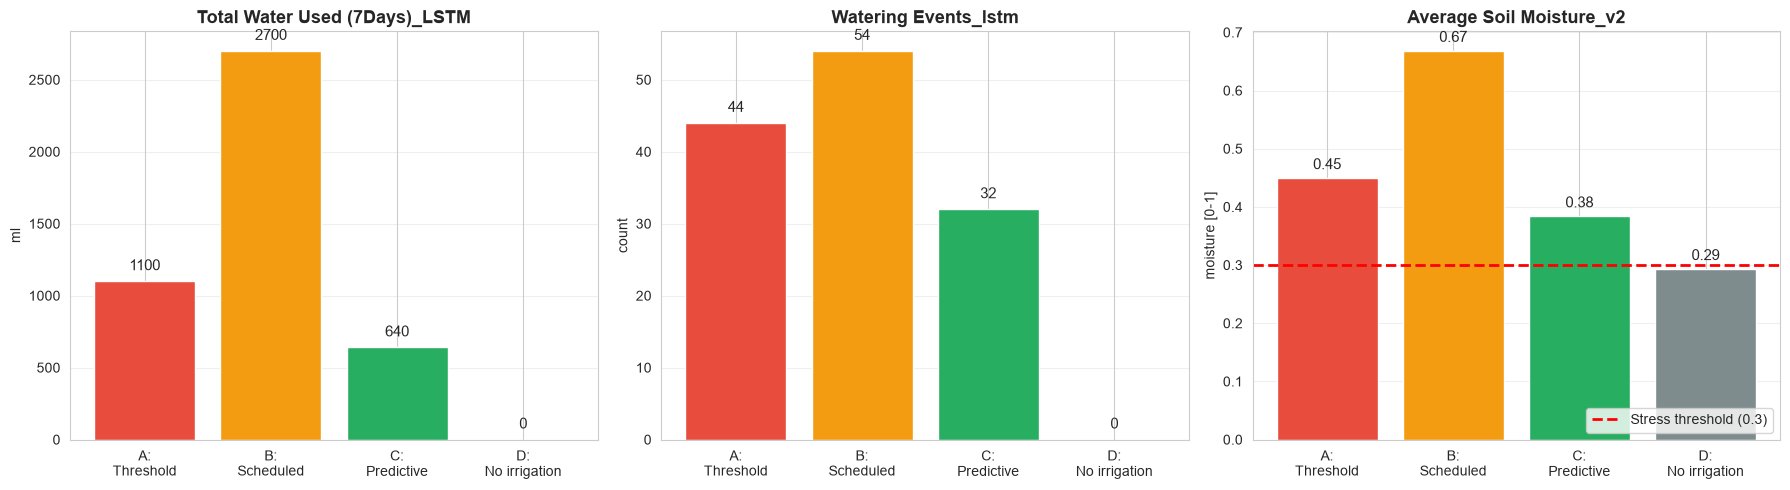

 Saved: docs/simulation_policy_comparison_lstm_7_days.png


In [7]:
pols = ["A", "B", "C", "D"]
labels = [f"{p}:\n{descriptions[p].split('(')[0].strip()}" for p in pols]
colors = {
    "A": "#e74c3c",   # red
    "B": "#f39c12",   # orange
    "C": "#27ae60",   # green
    "D": "#7f8c8d",   # gray
}
bar_colors = [colors[p] for p in pols]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ── Panel 1: total water ──
water = [summaries[p]["total_water_ml"] for p in pols]
axes[0].bar(labels, water, color=bar_colors)
axes[0].set_title("Total Water Used (7Days)_LSTM", fontsize=13, fontweight="bold")
axes[0].set_ylabel("ml")
for i, v in enumerate(water):
    axes[0].text(i, v + max(water) * 0.02, f"{v:.0f}",
                 ha="center", va="bottom", fontsize=11)
axes[0].grid(axis="y", alpha=0.3)

# ── Panel 2: watering events ──
events = [summaries[p]["water_events"] for p in pols]
axes[1].bar(labels, events, color=bar_colors)
axes[1].set_title("Watering Events_lstm", fontsize=13, fontweight="bold")
axes[1].set_ylabel("count")
for i, v in enumerate(events):
    axes[1].text(i, v + max(events) * 0.02, str(v),
                 ha="center", va="bottom", fontsize=11)
axes[1].grid(axis="y", alpha=0.3)

# ── Panel 3: average soil moisture ──
avg = [summaries[p]["avg_soil"] for p in pols]
axes[2].bar(labels, avg, color=bar_colors)
axes[2].axhline(config.POLICY_A_THRESHOLD, color="red", linestyle="--",
                linewidth=2, label=f"Stress threshold ({config.POLICY_A_THRESHOLD})")
axes[2].set_title("Average Soil Moisture_v2", fontsize=13, fontweight="bold")
axes[2].set_ylabel("moisture [0-1]")
for i, v in enumerate(avg):
    axes[2].text(i, v + 0.01, f"{v:.2f}", ha="center", va="bottom", fontsize=11)
axes[2].legend(loc="lower right")
axes[2].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(f"{config.DOCS_DIR}/simulation_policy_comparison_lstm_7_days.png",
            dpi=120, bbox_inches="tight")
plt.show()
print(f" Saved: docs/simulation_policy_comparison_lstm_7_days.png")

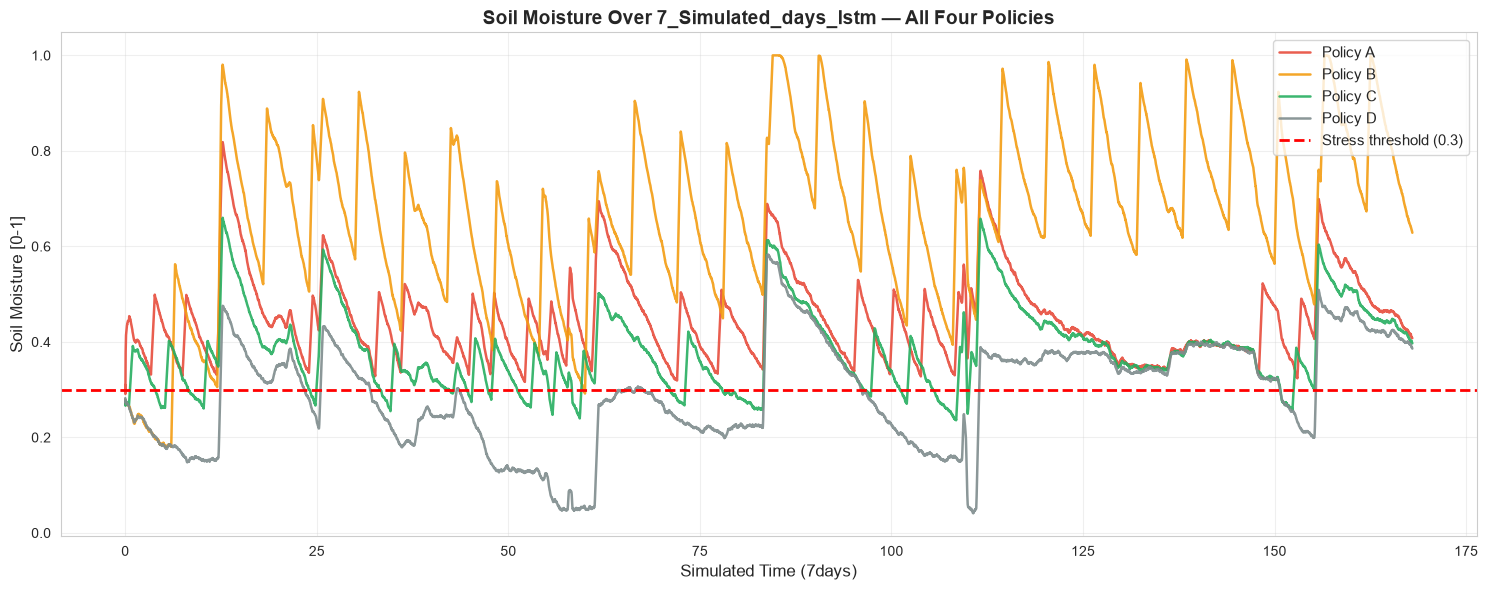

  How to read this plot:
   • D (gray)   — no irrigation, soil dives below threshold and stays there
   • A (red)    — water only when already dry; visible dips below threshold
   • B (orange) — constant watering keeps soil high (wastes water)
   • C (green)  — waters early enough to stay above threshold, with less water


In [8]:
fig, ax = plt.subplots(figsize=(15, 6))

for pol in ["A", "B", "C", "D"]:
    df = results[pol]
    # Smooth for readability (30-min rolling average)
    soil = df["soil"].rolling(30, min_periods=1).mean()
    ax.plot(df["sim_hours"], soil, label=f"Policy {pol}",
            color=colors[pol], alpha=0.9, linewidth=1.8)

ax.axhline(config.POLICY_A_THRESHOLD, color="red", linestyle="--",
           linewidth=2, label=f"Stress threshold ({config.POLICY_A_THRESHOLD})")

ax.set_xlabel("Simulated Time (7days)", fontsize=12)
ax.set_ylabel("Soil Moisture [0-1]", fontsize=12)
ax.set_title("Soil Moisture Over 7_Simulated_days_lstm — All Four Policies",
             fontsize=14, fontweight="bold")
ax.legend(loc="upper right", fontsize=11)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{config.DOCS_DIR}/simulation_soil_timeline_lstm_7_days.png",
            dpi=120, bbox_inches="tight")
plt.show()

print("  How to read this plot:")
print("   • D (gray)   — no irrigation, soil dives below threshold and stays there")
print("   • A (red)    — water only when already dry; visible dips below threshold")
print("   • B (orange) — constant watering keeps soil high (wastes water)")
print("   • C (green)  — waters early enough to stay above threshold, with less water")

In [9]:
out = {
    "experiment": "irrigation_policy_comparison_simulation",
    "steps": STEPS,
    "simulated_hours": STEPS / 60.0,
    "simulation_csv": os.path.basename(config.SIMULATION_CSV),
    "policy_threshold": config.POLICY_A_THRESHOLD,
    "used_trained_lstm": soil_model is not None,
    "summaries": summaries,
    "savings_vs_A_pct": {
        p: ((baseline_A - summaries[p]["total_water_ml"]) / baseline_A * 100)
           if baseline_A > 0 else 0.0
        for p in pols
    },
}

os.makedirs(config.DOCS_DIR, exist_ok=True)
with open(f"{config.DOCS_DIR}/simulation_results_lstm_7_days.json", "w") as f:
    json.dump(out, f, indent=2, default=str)

for pol in pols:
    results[pol].to_csv(f"{config.DOCS_DIR}/simulation_policy_lstm_7_days_{pol}.csv",
                        index=False)

print(f" Saved summary:     docs/simulation_results_lstm_7_days.json")
print(f" Saved per-policy:  docs/simulation_policy_lstm_7_days_*.csv")
print(f" Saved plots:       docs/simulation_policy_comparison_lstm_7_days.png")
print(f"                    docs/simulation_soil_timeline_lstm_7_days.png")

 Saved summary:     docs/simulation_results_lstm_7_days.json
 Saved per-policy:  docs/simulation_policy_lstm_7_days_*.csv
 Saved plots:       docs/simulation_policy_comparison_lstm_7_days.png
                    docs/simulation_soil_timeline_lstm_7_days.png


In [10]:

from datetime import datetime

final_results = {
    "experiment": "irrigation_policy_comparison_final",
    "timestamp": datetime.now().isoformat(),
    "dataset": "bhopal_agritech_dry_v2.csv",
    "used_trained_lstm": soil_model is not None,
    "lstm_test_mae": 0.042347,      
    "lstm_test_mse": 0.004701,
    "simulation_hours": 24,
    "steps_per_policy": 1440,
    "summaries": summaries,
    "water_savings_vs_A_pct": {
        p: (summaries["A"]["total_water_ml"] - summaries[p]["total_water_ml"]) / 
           summaries["A"]["total_water_ml"] * 100
        for p in ["A", "B", "C", "D"]
    },
}

os.makedirs(config.DOCS_DIR, exist_ok=True)
with open(f"{config.DOCS_DIR}/FINAL_results_lstm_7_days.json", "w") as f:
    json.dump(final_results, f, indent=2, default=str)

print(" Saved FINAL results to docs/FINAL_results_lstm_7_days.json")
print()
print(" HEADLINE RESULT")
print("=" * 60)
savings = final_results["water_savings_vs_A_pct"]
print(f"Policy C saved {savings['C']:.1f}% water vs Policy A")
print(f"Policy B saved {savings['B']:.1f}% water vs Policy A")
print(f"Policy D saved {savings['D']:.1f}% water vs Policy A (baseline)")
print()
print("Policy C details:")
print(f"  Water used:  {summaries['C']['total_water_ml']:.0f} ml")
print(f"  Avg soil:    {summaries['C']['avg_soil']:.3f}")
print(f"  Min soil:    {summaries['C']['min_soil']:.3f}")
print(f"  Events:      {summaries['C']['water_events']}")

 Saved FINAL results to docs/FINAL_results_lstm_7_days.json

 HEADLINE RESULT
Policy C saved 41.8% water vs Policy A
Policy B saved -145.5% water vs Policy A
Policy D saved 100.0% water vs Policy A (baseline)

Policy C details:
  Water used:  640 ml
  Avg soil:    0.384
  Min soil:    0.207
  Events:      32
